In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 01 — Download Sentinel-1 and WorldCover data (2021) on the data lab server

**What this notebook does**

1. Cleans up old upload zips (`data_part*.zip`, `data.zip`).
2. Defines **38 regions** (12 × 12 km each): 26 from round 1, 2 extra test regions, 10 new training regions (round 2).
3. **Checks each region before downloading**: Sentinel-1 images per month, best orbit direction, land-cover class mix.
4. Downloads, for every region, straight into `data/raw/` on this server:
   * `<region>_s1_2021.tif` — 12 monthly composites × 3 bands (VV, VH, VV−VH) = **36 bands**, dB × 100 (int16), no data = −9999
   * `<region>_label.tif` — ESA WorldCover 2021, original class codes
5. Saves `data/regions.csv`.

Re-running is safe: finished regions are skipped. **Run order on the server: 01 → 02 → 03.**

**Files needed in this folder:** `01_download_data.ipynb`, `02_preprocessing.ipynb`, `03_training.ipynb`, `preprocess.py`.

## 0. Clean up old zips, install packages, check internet

In [1]:
import glob, os
for z in glob.glob("data_part*.zip") + glob.glob("data.zip"):
    os.remove(z); print("deleted", z)
print("Free disk space here:", round(__import__("shutil").disk_usage(".").free / 1e9, 1), "GB  (need ~6 GB)")

Free disk space here: 1684.2 GB  (need ~6 GB)


In [2]:
import importlib, subprocess, sys
for pkg, mod in [("earthengine-api", "ee"), ("rasterio", "rasterio"), ("tqdm", "tqdm"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "--user", "-q",
                               "--no-warn-script-location", pkg])
        print("installed", pkg)
print("packages ok — if anything was installed, restart the kernel once (Kernel → Restart Kernel) and continue from the next cell")

import urllib.request
try:
    urllib.request.urlopen("https://earthengine.googleapis.com", timeout=10); print("Internet OK")
except Exception as e:
    print("Internet problem:", e)

packages ok — if anything was installed, restart the kernel once (Kernel → Restart Kernel) and continue from the next cell
Internet problem: HTTP Error 404: Not Found


## 0b. Log in to Earth Engine (first time on this server only)

If not logged in yet, this shows a **link**: open it, sign in with the Google account that owns the project, allow access, copy the code, paste it into the box and press Enter. The login is saved on the server for next time.

In [3]:
import ee
PROJECT = "your-ee-project"     # your Earth Engine Cloud project
try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate(auth_mode="notebook")
    ee.Initialize(project=PROJECT)
print("Earth Engine OK:", ee.ImageCollection("COPERNICUS/S1_GRD").limit(1).size().getInfo() == 1)


Successfully saved authorization token.
Earth Engine OK: True


In [4]:
import time, json
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import transform as warp_transform
from tqdm.auto import tqdm

YEAR      = 2021
SIZE_M    = 12_000                     # region side length in metres (12 km)
RES       = 10                         # pixel size in metres
N_PIX     = SIZE_M // RES              # 1200 x 1200 pixels per region
DATA      = Path("data")
RAW       = DATA / "raw"
RAW.mkdir(parents=True, exist_ok=True)
print("Saving to:", RAW.resolve())

Saving to: <project folder>/data/raw


## 1. Regions

**How these were chosen (put this reasoning in your report):**

* Cropland and Trees cover most of the Earth, so they appear in almost every region anyway.
  The *rare* classes — **Built-up, Bare, Water, Wetland, Grass/Shrub** — get dedicated regions so the model sees enough of them.
* Regions span Europe, Africa, Asia, the Americas and different climates, because the model may be tested anywhere.
* Every split (train / val / test) contains every class. Splits are **by region**, so the model is tested on places it never saw.
* The test split contains landscapes that are deliberately unlike the bulk of training (desert city, tropical delta, inland delta).
* Frankfurt (the planned case study) is **not** in any split.

Perfect balance is impossible — classes share regions — so the remaining imbalance is handled later with class weights in the loss. The check in Section 3 measures the balance before you download anything.

In [5]:
# name, lat, lon, main reason it is included, split
REGIONS = [
    # ---- Built-up (dense cities) -------------------------------------------
    ("paris",          48.860,    2.350, "Built-up",          "train"),
    ("delhi",          28.610,   77.210, "Built-up",          "train"),
    ("sao_paulo",     -23.550,  -46.630, "Built-up",          "train"),
    ("lagos",           6.520,    3.380, "Built-up, Water",   "train"),
    ("rhine_neckar",   49.450,    8.550, "Mixed Europe",      "train"),
    ("madrid",         40.420,   -3.700, "Built-up, Grass",   "val"),
    ("cairo",          30.050,   31.240, "Built-up, Bare",    "test"),
    # ---- Bare -------------------------------------------------------------
    ("riyadh",         24.710,   46.680, "Bare, Built-up",    "train"),
    ("phoenix_west",   33.450, -112.450, "Bare, Cropland",    "train"),
    ("las_vegas",      36.170, -115.140, "Bare, Built-up",    "val"),
    # ---- Water --------------------------------------------------------------
    ("lake_constance", 47.600,    9.400, "Water",             "train"),
    ("finland_lahti",  61.000,   25.600, "Trees, Water",      "train"),
    ("manaus",         -3.100,  -60.020, "Trees, Water",      "train"),
    # ---- Wetland ------------------------------------------------------------
    ("wadden_coast",   53.170,    5.420, "Wetland, Water",    "train"),
    ("sundarbans",     22.000,   89.300, "Wetland (mangrove)", "train"),
    ("everglades",     25.800,  -80.700, "Wetland",           "train"),
    ("danube_delta",   45.150,   29.350, "Wetland, Water",    "val"),
    ("okavango",      -19.300,   22.900, "Wetland, Grass",    "test"),
    # ---- Grass / Shrub ----------------------------------------------------
    ("nairobi_plains", -1.500,   36.950, "Grass/Shrub",       "train"),
    ("ulaanbaatar",    47.920,  106.920, "Grass, Built-up",   "train"),
    ("montana",        47.000, -108.000, "Grass/Shrub",       "train"),
    # ---- Trees ------------------------------------------------------------
    ("black_forest",   48.050,    8.200, "Trees",             "test"),
    # ---- Cropland -----------------------------------------------------------
    ("iowa",           42.030,  -93.620, "Cropland",          "val"),
    ("punjab",         30.900,   75.850, "Cropland, Built-up", "train"),
    ("beauce",         48.200,    1.700, "Cropland",          "train"),
    ("mekong_delta",   10.030,  105.780, "Cropland, Water",   "test"),
    # ---- extra test regions (more Cropland and Bare in test) ---------------
    ("hungary_plain",   46.950,   20.650, "Cropland",          "test"),
    ("namib_desert",   -22.550,   14.750, "Bare",              "test"),
    # ---- round 2: more varied wetland (reeds / marsh / floodplain) ---------
    ("biebrza_marsh",  53.450,   22.550, "Wetland (reed/marsh)", "train"),
    ("camargue",       43.550,    4.550, "Wetland, Water",       "train"),
    ("pantanal",      -18.000,  -57.500, "Wetland, Grass",       "train"),
    # ---- round 2: rural cropland (no big city) -----------------------------
    ("ukraine_fields", 49.400,   33.000, "Cropland",             "train"),
    ("kansas",         38.500,  -98.500, "Cropland, Grass",      "train"),
    ("nile_delta",     30.800,   31.000, "Cropland",             "train"),
    ("po_valley",      45.100,    9.800, "Cropland",             "train"),
    # ---- round 2: pure desert (bare rock / sand) ---------------------------
    ("western_desert", 25.000,   29.000, "Bare",                 "train"),
    ("atacama",       -23.500,  -69.500, "Bare",                 "train"),
    # ---- round 2: steppe / shrubland ---------------------------------------
    ("kazakh_steppe",  51.000,   70.000, "Grass/Shrub",          "train"),
]
regions = pd.DataFrame(REGIONS, columns=["name", "lat", "lon", "reason", "split"])
print(regions.split.value_counts().to_string())
regions

split
train    28
test      6
val       4


,name,lat,lon,reason,split
0,paris,48.86,2.35,Built-up,train
1,delhi,28.61,77.21,Built-up,train
2,sao_paulo,-23.55,-46.63,Built-up,train
3,lagos,6.52,3.38,"Built-up, Water",train
4,rhine_neckar,49.45,8.55,Mixed Europe,train
5,madrid,40.42,-3.70,"Built-up, Grass",val
6,cairo,30.05,31.24,"Built-up, Bare",test
7,riyadh,24.71,46.68,"Bare, Built-up",train
8,phoenix_west,33.45,-112.45,"Bare, Cropland",train
9,las_vegas,36.17,-115.14,"Bare, Built-up",val


## 2. Helper functions

* `region_grid` — builds an exact 10 m pixel grid in the local **UTM** zone (metres, square pixels).
  Both the radar and the label are downloaded on **this same grid**, so pixel (i, j) is the same ground in both files.
* `s1_month` — the monthly composite. Earth Engine's `COPERNICUS/S1_GRD` is already calibrated, terrain corrected and in dB.
  We convert to linear power, **average all images of the month** (this also reduces speckle), convert back to dB and add the ratio band.

In [6]:
def utm_epsg(lat, lon):
    zone = int((lon + 180) // 6) + 1
    return f"EPSG:{(32600 if lat >= 0 else 32700) + zone}"

def region_grid(lat, lon):
    crs = utm_epsg(lat, lon)
    xs, ys = warp_transform("EPSG:4326", crs, [lon], [lat])
    x0 = round((xs[0] - SIZE_M / 2) / RES) * RES     # top-left corner, snapped to 10 m
    y0 = round((ys[0] + SIZE_M / 2) / RES) * RES
    grid = {"dimensions": {"width": N_PIX, "height": N_PIX},
            "affineTransform": {"scaleX": RES, "shearX": 0, "translateX": x0,
                                "shearY": 0, "scaleY": -RES, "translateY": y0},
            "crsCode": crs}
    aoi = ee.Geometry.Rectangle([x0, y0 - SIZE_M, x0 + SIZE_M, y0],
                                proj=crs, geodesic=False)
    return crs, x0, y0, grid, aoi

def s1_collection(aoi, start, end, orbit):
    return (ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(aoi).filterDate(start, end)
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
            .filter(ee.Filter.eq("resolution_meters", 10))
            .filter(ee.Filter.eq("orbitProperties_pass", orbit)))

def s1_month(aoi, year, month, orbit):
    start = ee.Date.fromYMD(year, month, 1)
    col = s1_collection(aoi, start, start.advance(1, "month"), orbit)
    def to_linear(img):
        vv_vh = img.select(["VV", "VH"])
        vv_vh = vv_vh.updateMask(img.select("VV").gt(-30))      # remove edge noise
        return ee.Image(10).pow(vv_vh.divide(10))                 # dB -> linear power
    mean_lin = col.map(to_linear).mean()                          # average in LINEAR
    db = mean_lin.log10().multiply(10)                            # back to dB
    ratio = db.select("VV").subtract(db.select("VH")).rename("VV_VH")
    out = db.addBands(ratio).select(["VV", "VH", "VV_VH"])
    return out.multiply(100).round().unmask(-9999).toInt16()      # dB x 100

WORLDCOVER = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")   # = 2021

## 3. Check every region before downloading

For each region this asks Earth Engine (quickly, nothing is downloaded yet):

* how many Sentinel-1 images exist per month for **ascending** and **descending** orbits → picks the better one and uses it for the whole year (mixing both blends two viewing angles);
* the WorldCover class mix inside the region.

**What to look for:** every month should have ≥ 2 images in the chosen orbit, and the class table at the end should show every class in every split.

In [7]:
from collections import Counter

def check_region(lat, lon):
    crs, x0, y0, grid, aoi = region_grid(lat, lon)
    col = s1_collection(aoi, f"{YEAR}-01-01", f"{YEAR + 1}-01-01", "ASCENDING") \
            .merge(s1_collection(aoi, f"{YEAR}-01-01", f"{YEAR + 1}-01-01", "DESCENDING"))
    hist = WORLDCOVER.reduceRegion(ee.Reducer.frequencyHistogram(), aoi,
                                   scale=RES, crs=crs, maxPixels=1e9).get("Map")
    info = ee.Dictionary({"time": col.aggregate_array("system:time_start"),
                          "pass": col.aggregate_array("orbitProperties_pass"),
                          "hist": hist}).getInfo()
    months = pd.to_datetime(info["time"], unit="ms").month
    counts = {p: Counter(m for m, q in zip(months, info["pass"]) if q == p)
              for p in ("ASCENDING", "DESCENDING")}
    def score(p):   # months with >= 2 images first, then total images
        return (sum(counts[p][m] >= 2 for m in range(1, 13)), sum(counts[p].values()))
    orbit = max(("DESCENDING", "ASCENDING"), key=score)
    n_month = [counts[orbit][m] for m in range(1, 13)]
    return orbit, n_month, {int(k): v for k, v in (info["hist"] or {}).items()}

rows, hists = [], {}
for r in tqdm(regions.itertuples(), total=len(regions)):
    orbit, n_month, hist = check_region(r.lat, r.lon)
    hists[r.name] = hist
    rows.append({"name": r.name, "orbit": orbit, "min_images": min(n_month),
                 "images_per_month": " ".join(map(str, n_month))})
check = pd.DataFrame(rows)
regions = regions.drop(columns=[c for c in ["orbit", "min_images", "images_per_month"]
                                if c in regions]).merge(check, on="name")
regions.to_csv(DATA / "regions.csv", index=False)
with open(DATA / "worldcover_histograms.json", "w") as f:
    json.dump(hists, f)
regions[["name", "split", "orbit", "min_images", "images_per_month"]]

  0%|          | 0/38 [00:00<?, ?it/s]

,name,split,orbit,min_images,images_per_month
0,paris,train,DESCENDING,7,10 7 10 10 10 10 11 11 10 10 10 9
1,delhi,train,DESCENDING,4,5 5 5 5 5 5 5 5 5 5 4 4
2,sao_paulo,train,DESCENDING,3,5 4 5 5 5 5 5 4 5 3 5 5
3,lagos,train,ASCENDING,2,3 2 3 2 3 3 2 3 2 3 2 3
4,rhine_neckar,train,DESCENDING,7,8 7 8 10 10 10 9 9 10 10 10 8
5,madrid,val,DESCENDING,7,11 7 11 10 11 10 10 9 10 10 10 9
6,cairo,test,ASCENDING,5,5 5 5 5 5 5 5 5 5 5 5 5
7,riyadh,train,ASCENDING,2,3 2 3 2 3 2 3 2 3 2 3 2
8,phoenix_west,train,ASCENDING,6,7 8 7 8 7 8 7 9 8 7 6 6
9,las_vegas,val,DESCENDING,4,6 4 5 5 6 5 5 5 5 5 5 5


Class share per region (%)


,split,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
paris,train,15.3,1.0,0.1,81.9,0.1,1.8,0.0
delhi,train,40.8,3.1,3.7,50.4,0.5,1.5,0.0
sao_paulo,train,9.3,1.4,0.2,88.3,0.2,0.6,0.0
lagos,train,2.2,2.1,0.1,62.5,0.2,29.2,3.7
rhine_neckar,train,24.5,11.8,30.3,29.3,0.2,3.9,0.0
madrid,val,25.0,9.0,0.4,64.7,0.7,0.2,0.0
cairo,test,2.2,0.8,1.2,84.4,7.1,4.4,0.0
riyadh,train,2.4,0.3,0.8,77.8,18.6,0.0,0.0
phoenix_west,train,4.0,14.5,25.3,26.8,29.3,0.1,0.0
las_vegas,val,3.2,2.8,0.0,83.8,9.9,0.3,0.0


Class share per split (%)  — every class should be > 0 in every split


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
split,,,,,,,
test,21.7,15.8,12.3,20.3,18.0,3.8,8.2
train,11.8,13.8,21.2,23.9,9.3,10.8,9.2
val,14.4,9.4,9.4,41.5,2.8,5.3,17.1


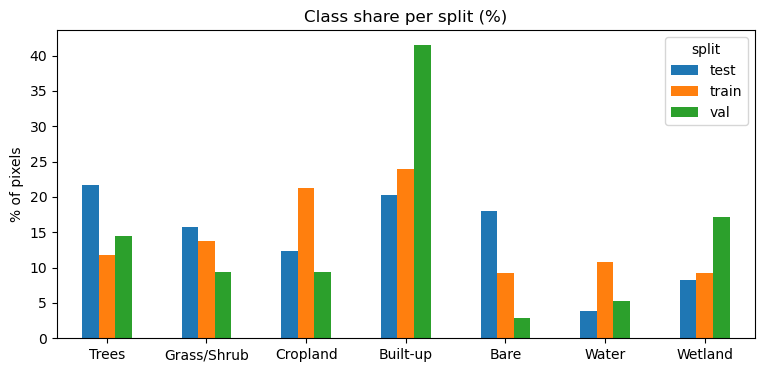

In [8]:
# Class mix per region and per split (our 7 classes, % of pixels)
import sys; sys.path.append(".")
from preprocess import CLASSES, WORLDCOVER_TO_CLASS

def to_classes(hist):
    v = np.zeros(len(CLASSES))
    for code, n in hist.items():
        if code in WORLDCOVER_TO_CLASS:
            v[WORLDCOVER_TO_CLASS[code]] += n
    return v

mix = pd.DataFrame({n: to_classes(h) for n, h in hists.items()}, index=CLASSES).T
mix_pct = (100 * mix.div(mix.sum(axis=1), axis=0)).round(1)
mix_pct.insert(0, "split", regions.set_index("name").split)
print("Class share per region (%)")
display(mix_pct)

split_pct = mix.groupby(regions.set_index("name").split).sum()
split_pct = (100 * split_pct.div(split_pct.sum(axis=1), axis=0)).round(1)
print("Class share per split (%)  — every class should be > 0 in every split")
display(split_pct)

ax = split_pct.T.plot.bar(figsize=(9, 4), rot=0, title="Class share per split (%)")
ax.set_ylabel("% of pixels");

**Read the two tables before continuing.**

* If a region has `min_images` = 0 or 1, it still works (that month is just noisier or partly empty), but note it.
* If a class is below ~2 % in **train**, add a region rich in that class (copy a line in Section 1, change name/lat/lon, re-run from Section 1).
* If a region turns out to be almost all one common class (e.g. 95 % cropland), you may swap it.
* `Bare` and `Wetland` are usually the rarest — this is expected and is why they have their own regions.

## 4. Download everything

One region at a time, the 12 months are downloaded in parallel (4 at once). Each month is about 9 MB; each region about 100 MB uncompressed, ~40–60 MB on disk.
**Expect roughly 20–40 minutes for all 38 regions** on the server, depending on your internet and Earth Engine load. You can stop and re-run any time — finished regions are skipped.

In [9]:
def fetch(expression, grid, tries=5):
    for k in range(tries):
        try:
            return ee.data.computePixels({"expression": expression,
                                          "fileFormat": "NUMPY_NDARRAY", "grid": grid})
        except Exception as e:                      # quota / network hiccup -> wait, retry
            if k == tries - 1:
                raise
            wait = 10 * (k + 1)
            print(f"   retry in {wait}s ({str(e)[:80]})")
            time.sleep(wait)

def download_region(r):
    s1_path, lab_path = RAW / f"{r.name}_s1_{YEAR}.tif", RAW / f"{r.name}_label.tif"
    if s1_path.exists() and lab_path.exists():
        return "skipped (already downloaded)"
    crs, x0, y0, grid, aoi = region_grid(r.lat, r.lon)
    profile = dict(driver="GTiff", width=N_PIX, height=N_PIX, crs=crs,
                   transform=from_origin(x0, y0, RES, RES),
                   compress="deflate", tiled=True, blockxsize=256, blockysize=256)

    # --- Sentinel-1: 12 months x 3 bands
    def one_month(m):
        a = fetch(s1_month(aoi, YEAR, m, r.orbit), grid)
        return np.stack([a["VV"], a["VH"], a["VV_VH"]]).astype(np.int16)
    with ThreadPoolExecutor(max_workers=4) as pool:
        months = list(pool.map(one_month, range(1, 13)))
    stack = np.concatenate(months)                        # (36, 1200, 1200)
    tmp = s1_path.with_suffix(".tmp")
    with rasterio.open(tmp, "w", count=36, dtype="int16", nodata=-9999,
                       predictor=2, **profile) as dst:
        dst.write(stack)
        for m in range(12):
            for b, band in enumerate(["VV", "VH", "VV_VH"]):
                dst.set_band_description(3 * m + b + 1, f"{YEAR}-{m + 1:02d}_{band}")
        dst.update_tags(units="dB x 100", orbit=r.orbit, source="COPERNICUS/S1_GRD")
    tmp.replace(s1_path)                                  # only complete files get the real name

    # --- WorldCover label (nearest neighbour: class codes stay whole numbers)
    lab = fetch(WORLDCOVER.unmask(0).toUint8(), grid)["Map"].astype(np.uint8)
    with rasterio.open(lab_path, "w", count=1, dtype="uint8", nodata=0, **profile) as dst:
        dst.write(lab, 1)
        dst.update_tags(source="ESA/WorldCover/v200 (2021)", values="original WorldCover codes")
    return "done"

t0 = time.time()
for r in tqdm(list(regions.itertuples()), desc="regions"):
    print(f"{r.name:16s} {r.orbit:10s} ->", download_region(r))
print(f"Finished in {(time.time() - t0) / 60:.1f} min")

regions:   0%|          | 0/38 [00:00<?, ?it/s]

paris            DESCENDING -> done
delhi            DESCENDING -> done
sao_paulo        DESCENDING -> done
lagos            ASCENDING  -> done
rhine_neckar     DESCENDING -> done
madrid           DESCENDING -> done
cairo            ASCENDING  -> done
riyadh           ASCENDING  -> done
phoenix_west     ASCENDING  -> done
las_vegas        DESCENDING -> done
lake_constance   ASCENDING  -> done
finland_lahti    ASCENDING  -> done
manaus           DESCENDING -> done
wadden_coast     ASCENDING  -> done
sundarbans       ASCENDING  -> done
everglades       ASCENDING  -> done
danube_delta     ASCENDING  -> done
okavango         ASCENDING  -> done
nairobi_plains   ASCENDING  -> done
ulaanbaatar      DESCENDING -> done
montana          DESCENDING -> done
black_forest     DESCENDING -> done
iowa             ASCENDING  -> done
punjab           ASCENDING  -> done
beauce           ASCENDING  -> done
mekong_delta     DESCENDING -> done
hungary_plain    DESCENDING -> done
namib_desert     ASCENDING  

## 5. Quick check of the downloaded files

* Every region must have both files, the same size (1200 × 1200) and the same CRS.
* `nodata %` per month should be small (0–5 %). A month with a high value had poor coverage — note it.
* Then look at one region: VV should show bright cities, dark water; the label should line up with it.

In [10]:
import matplotlib.pyplot as plt
from preprocess import decode_s1

qc = []
for r in regions.itertuples():
    s1p, lp = RAW / f"{r.name}_s1_{YEAR}.tif", RAW / f"{r.name}_label.tif"
    with rasterio.open(s1p) as a, rasterio.open(lp) as b:
        same = (a.shape == b.shape) and (a.crs == b.crs) and (a.transform == b.transform)
        raw = a.read(); shape = a.shape
    nod = (raw.reshape(12, 3, -1)[:, 0] == -9999).mean(1) * 100
    qc.append({"name": r.name, "aligned": same, "shape": shape,
               "max nodata % (month)": round(nod.max(), 1),
               "nodata % per month": " ".join(f"{v:.0f}" for v in nod),
               "MB on disk": round((s1p.stat().st_size + lp.stat().st_size) / 1e6, 1)})
qc = pd.DataFrame(qc)
print("All regions aligned:", qc.aligned.all(), "| total size:", round(qc["MB on disk"].sum() / 1e3, 2), "GB")
qc

All regions aligned: True | total size: 2.86 GB


,name,aligned,shape,max nodata % (month),nodata % per month,MB on disk
0,paris,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,77.4
1,delhi,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,77.6
2,sao_paulo,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,77.8
3,lagos,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,77.5
4,rhine_neckar,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,74.8
5,madrid,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,77.6
6,cairo,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,77.2
7,riyadh,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,78.5
8,phoenix_west,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,75.9
9,las_vegas,True,"(1200, 1200)",0.0,0 0 0 0 0 0 0 0 0 0 0 0,77.5


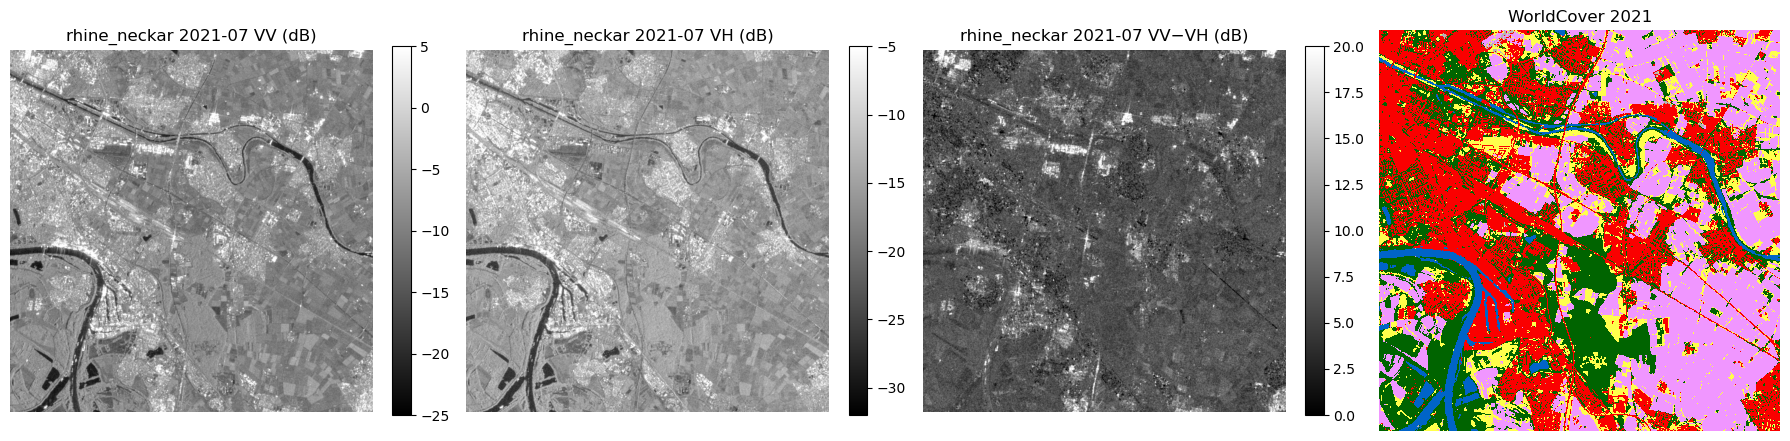

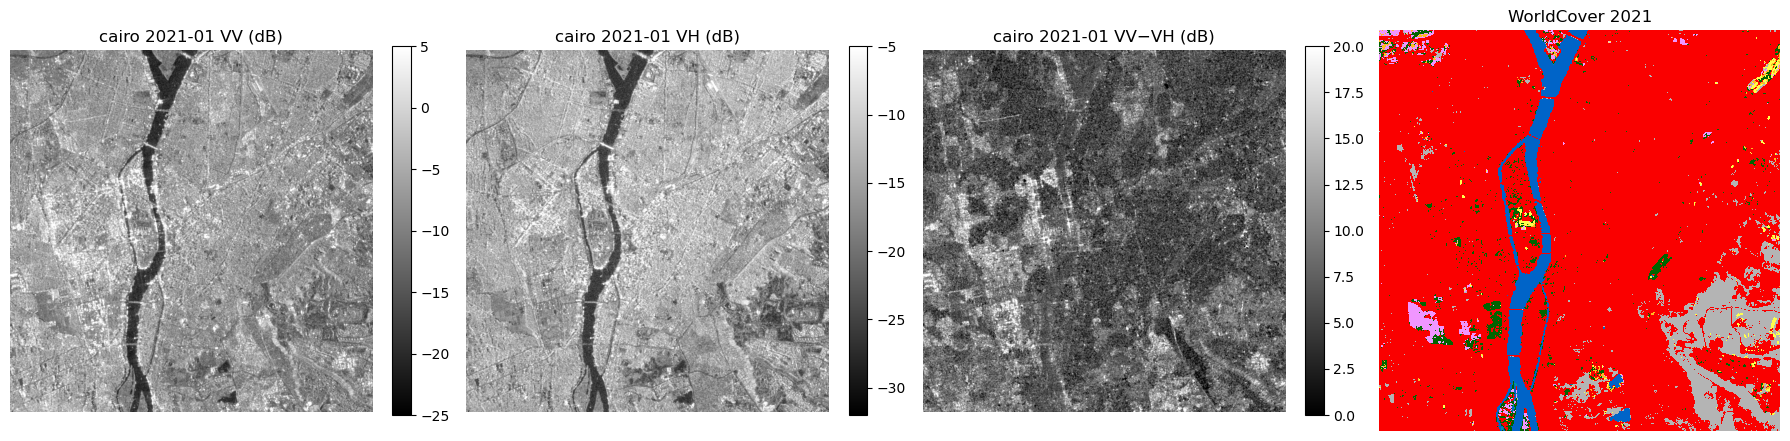

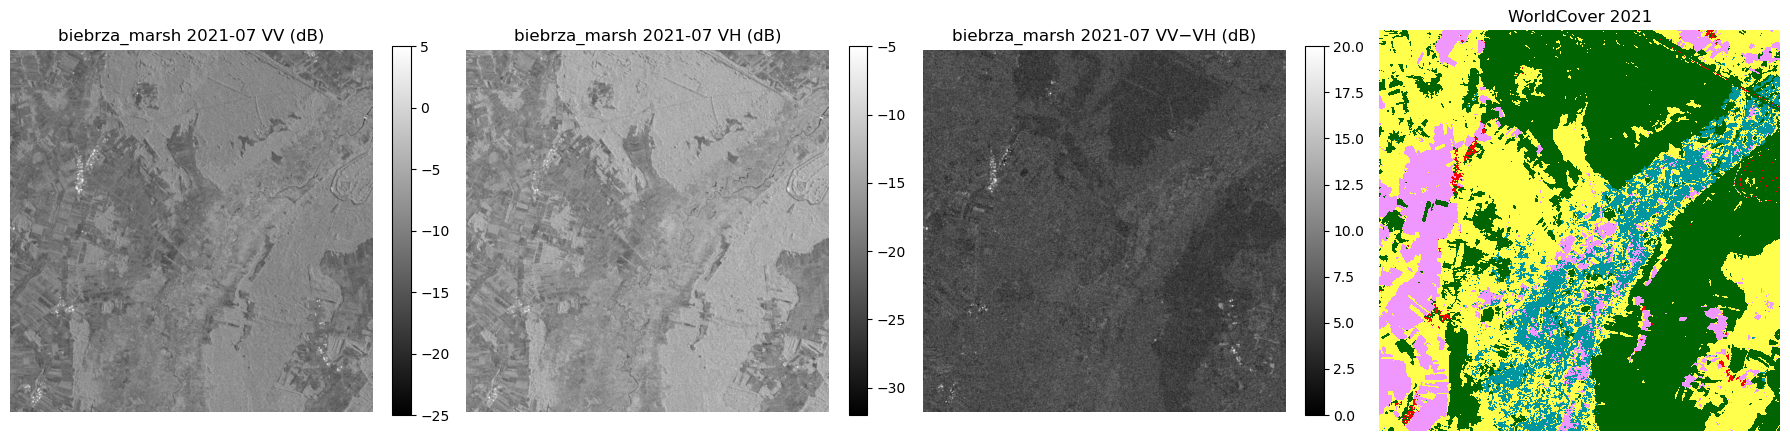

In [11]:
from matplotlib.colors import ListedColormap, BoundaryNorm
WC_CODES  = [10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100]
WC_COLORS = ["#006400", "#ffbb22", "#ffff4c", "#f096ff", "#fa0000", "#b4b4b4",
             "#f0f0f0", "#0064c8", "#0096a0", "#00cf75", "#fae6a0"]   # official WorldCover colours
wc_cmap = ListedColormap(WC_COLORS)
wc_norm = BoundaryNorm(WC_CODES + [101], wc_cmap.N)

def show_region(name, month=7):
    with rasterio.open(RAW / f"{name}_s1_{YEAR}.tif") as f:
        x = decode_s1(f.read().reshape(12, 3, N_PIX, N_PIX))[month - 1]
    with rasterio.open(RAW / f"{name}_label.tif") as f:
        y = f.read(1)
    fig, ax = plt.subplots(1, 4, figsize=(18, 5))
    for a, img, t, lim in zip(ax, x, ["VV (dB)", "VH (dB)", "VV−VH (dB)"],
                              [(-25, 5), (-32, -5), (0, 20)]):
        im = a.imshow(img, cmap="gray", vmin=lim[0], vmax=lim[1]); a.set_title(f"{name} {YEAR}-{month:02d} {t}")
        plt.colorbar(im, ax=a, fraction=0.046)
    ax[3].imshow(y, cmap=wc_cmap, norm=wc_norm, interpolation="nearest"); ax[3].set_title("WorldCover 2021")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

show_region("rhine_neckar", month=7)
show_region("cairo", month=1)
show_region("biebrza_marsh", month=7)

✅ When the tables look fine and the images line up, continue with **02_preprocessing.ipynb**.

In [14]:
import numpy as np, pandas as pd, rasterio
VALID = {0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95, 100}
rows = []
for r in regions.itertuples():
    with rasterio.open(RAW / f"{r.name}_label.tif") as f:
        lab = f.read(1)
    codes, counts = np.unique(lab, return_counts=True)
    local = dict(zip(codes.tolist(), counts.tolist()))
    ee_hist = hists[r.name]                                  # counted by Earth Engine in Section 3
    diff = sum(abs(local.get(c, 0) - ee_hist.get(c, 0)) for c in set(local) | set(ee_hist)) / lab.size * 100
    rows.append({"name": r.name, "codes in file": sorted(local),
                 "invalid codes": sorted(set(local) - VALID) or "none",
                 "differs from EE (%)": round(diff, 2)})
pd.DataFrame(rows)

,name,codes in file,invalid codes,differs from EE (%)
0,paris,"[10, 30, 40, 50, 60, 80]",none,0.0
1,delhi,"[10, 20, 30, 40, 50, 60, 80, 90]",none,0.0
2,sao_paulo,"[10, 30, 40, 50, 60, 80]",none,0.0
3,lagos,"[10, 20, 30, 40, 50, 60, 80, 90, 95]",none,0.0
4,rhine_neckar,"[10, 30, 40, 50, 60, 80, 90]",none,0.0
5,madrid,"[10, 20, 30, 40, 50, 60, 80]",none,0.0
6,cairo,"[10, 20, 30, 40, 50, 60, 80, 90]",none,0.0
7,riyadh,"[10, 20, 30, 40, 50, 60, 80]",none,0.0
8,phoenix_west,"[10, 20, 30, 40, 50, 60, 80]",none,0.0
9,las_vegas,"[10, 20, 30, 40, 50, 60, 80, 90]",none,0.0


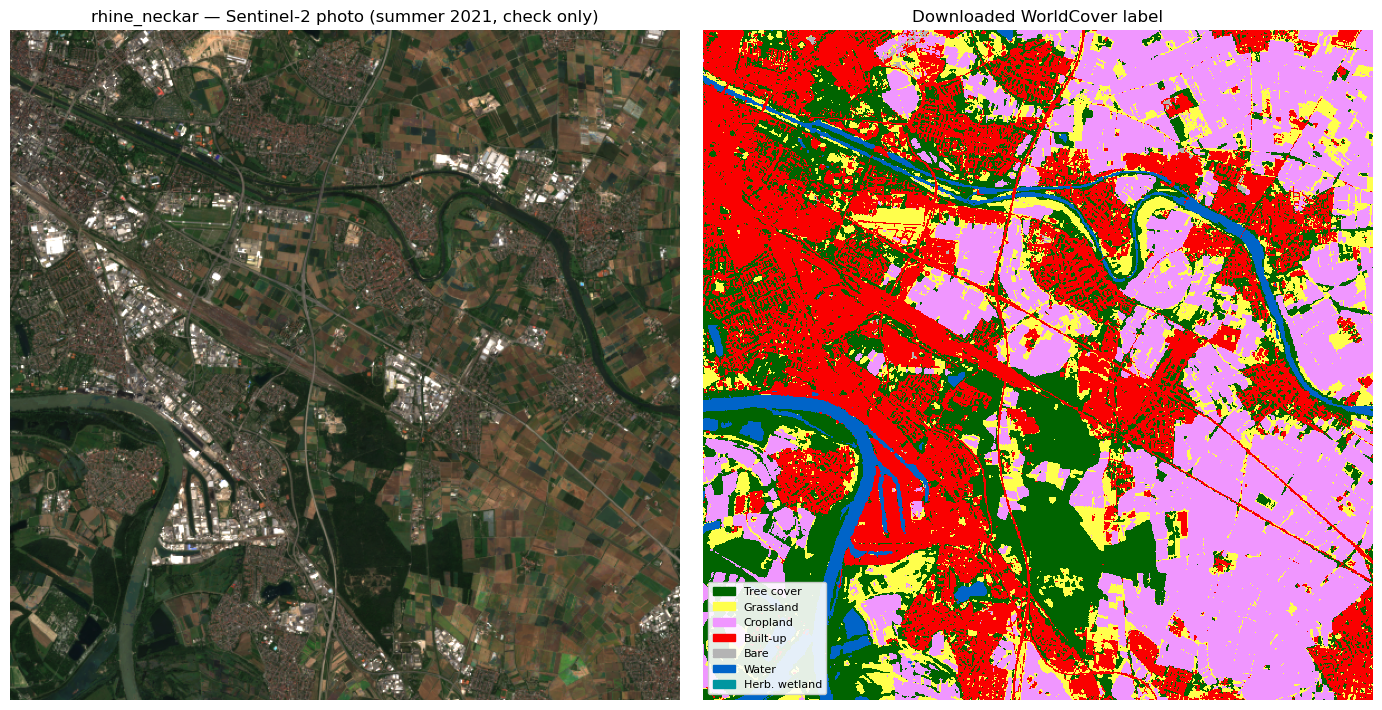

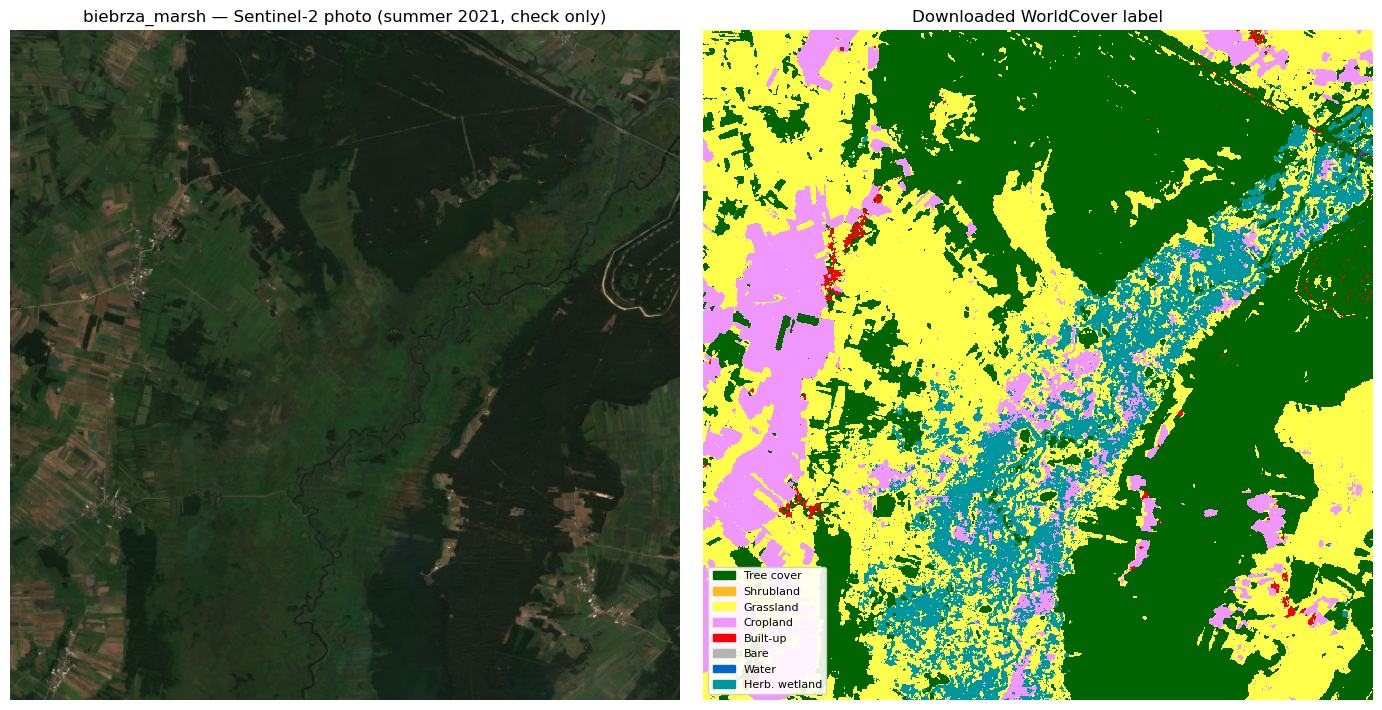

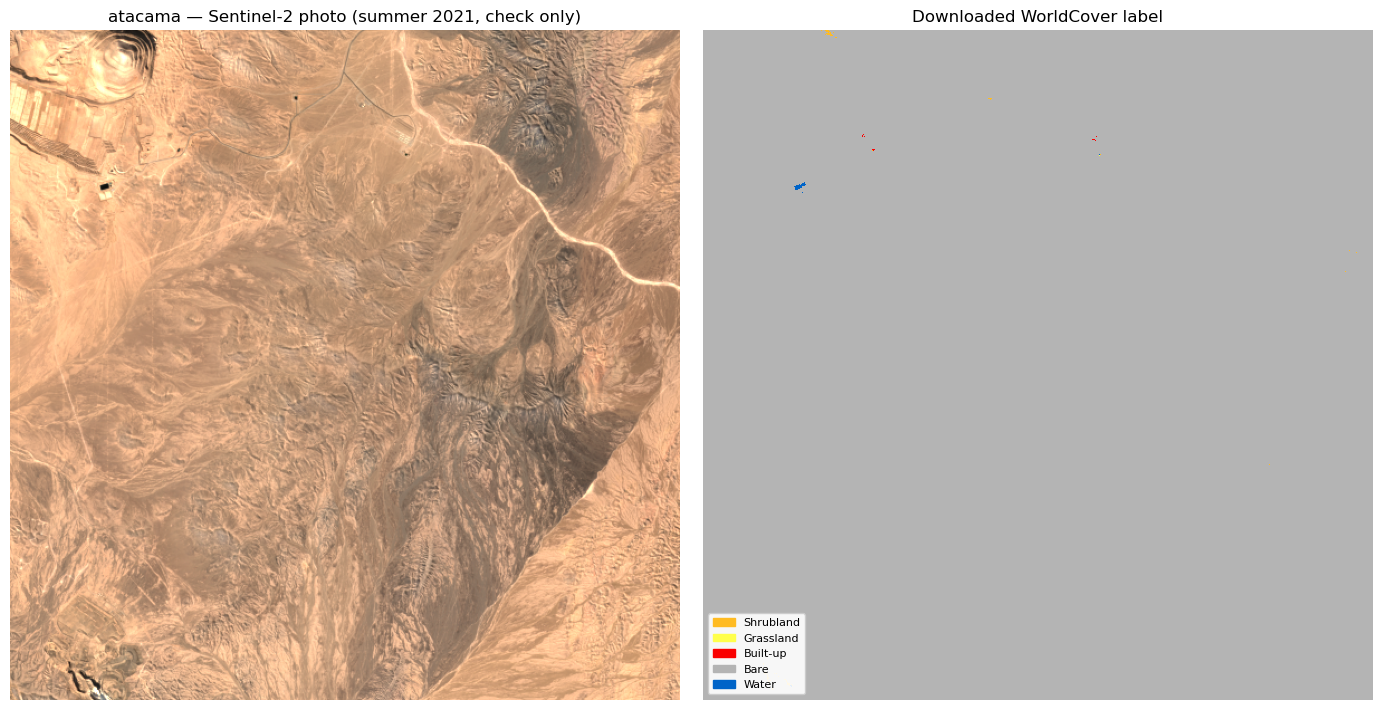

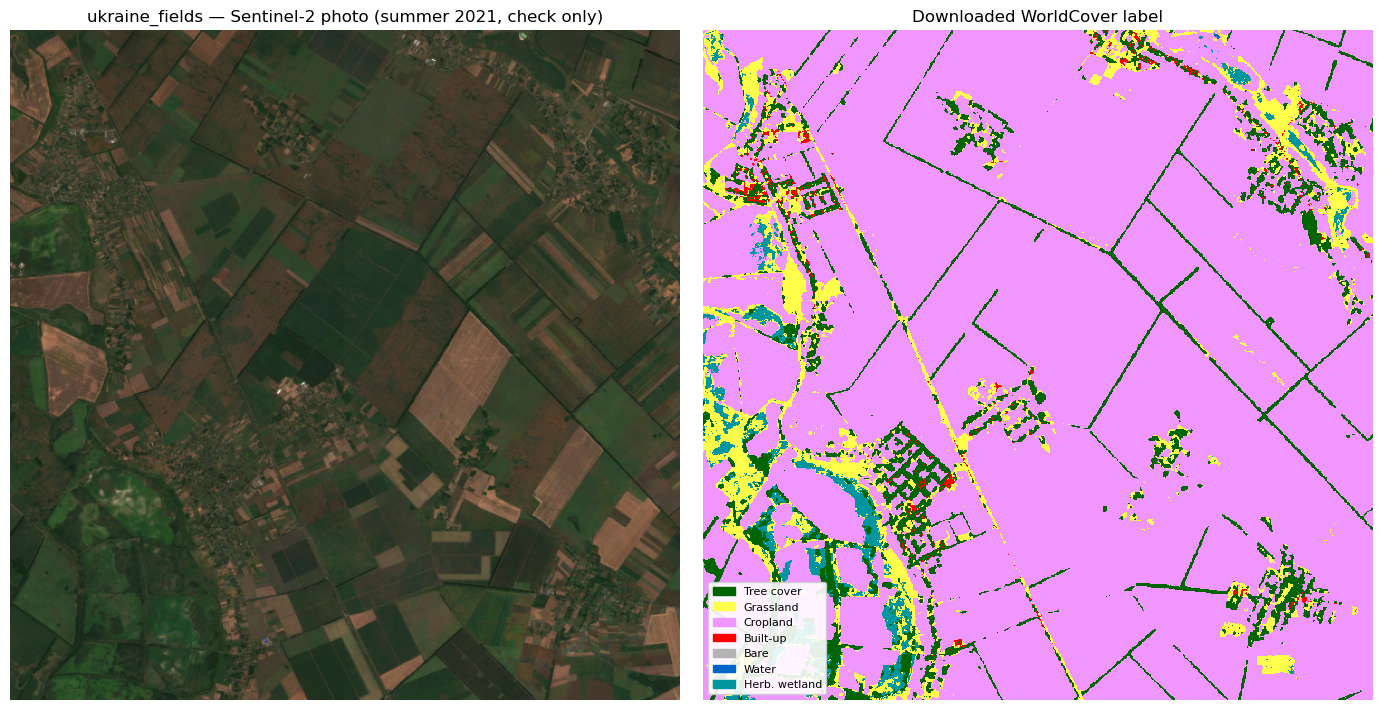

In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from PIL import Image
import requests, io

WC = {10: ("Tree cover", "#006400"), 20: ("Shrubland", "#ffbb22"), 30: ("Grassland", "#ffff4c"),
      40: ("Cropland", "#f096ff"), 50: ("Built-up", "#fa0000"), 60: ("Bare", "#b4b4b4"),
      70: ("Snow/ice", "#f0f0f0"), 80: ("Water", "#0064c8"), 90: ("Herb. wetland", "#0096a0"),
      95: ("Mangroves", "#00cf75"), 100: ("Moss", "#fae6a0")}
codes = list(WC)
cmap = ListedColormap([WC[c][1] for c in codes]); norm = BoundaryNorm(codes + [101], cmap.N)

def photo(name):
    r = regions.set_index("name").loc[name]
    crs, x0, y0, grid, aoi = region_grid(r.lat, r.lon)
    s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(aoi)
          .filterDate("2021-04-01", "2021-10-01")
          .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 20)).median())
    url = s2.visualize(bands=["B4", "B3", "B2"], min=0, max=3000).getThumbURL(
        {"region": aoi, "dimensions": 600, "crs": crs, "format": "png"})
    return Image.open(io.BytesIO(requests.get(url).content))

def check_labels(name):
    with rasterio.open(RAW / f"{name}_label.tif") as f:
        lab = f.read(1)
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    ax[0].imshow(photo(name)); ax[0].set_title(f"{name} — Sentinel-2 photo (summer 2021, check only)")
    ax[1].imshow(lab, cmap=cmap, norm=norm, interpolation="nearest"); ax[1].set_title("Downloaded WorldCover label")
    present = [c for c in codes if (lab == c).any()]
    ax[1].legend(handles=[Patch(color=WC[c][1], label=WC[c][0]) for c in present],
                 loc="lower left", fontsize=8, framealpha=0.9)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

for name in ["rhine_neckar", "biebrza_marsh", "atacama", "ukraine_fields"]:
    check_labels(name)